In [1]:
from tensorflow import keras
from sklearn.model_selection import train_test_split

In [2]:
(train_input, train_target), (test_input, test_target) = \
    keras.datasets.fashion_mnist.load_data()

In [3]:
print(train_input.shape)
print(test_input.shape)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
train_scaled = train_input.reshape(-1, 28, 28, 1) / 255.0  # 4차원 (데이터개수, 행, 열, 채널)
test_scaled  = test_input.reshape(-1, 28 ,28, 1) / 255.0


train_scaled, val_scaled, train_target, val_target = \
    train_test_split(train_scaled
                   , train_target
                   , test_size    = 0.2
                   , random_state = 42) # 훈련데이터, 검증데이터, 테스트 데이터 구성 

In [5]:
# CNN(합성곱) 신경망 구성
model = keras.Sequential()
model.add(keras.Input(shape = (28, 28, 1)))
model.add(keras.layers.Conv2D(filters      = 32
                            , kernel_size  = (3, 3)
                            , padding      = 'same'
                            , strides      = 1
                            , activation   = 'relu')) # 필터 사이즈

model.add(keras.layers.MaxPooling2D(pool_size =  (2,2)))
model.add(keras.layers.Conv2D(
          filters=64,
          kernel_size=(3, 3),
          padding='same',
          strides=1,
          activation='relu'
))

model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))  # 참조: # AveragePooling2D()

In [6]:
# 완전 연결 계층
model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(units      = 100
                           , activation = 'relu'))
model.add(keras.layers.Dropout(0.4))
model.add(keras.layers.Dense(units      = 10
                           , activation = 'softmax')) # 항상 마지막단 다중분류 소프트맥스


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       313,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,526 (1.27 MB)

 Trainable params: 333,526 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
## 참고 - 위와 동일 코드
# model = keras.Sequential([
#     keras.Input(shape=(28, 28, 1)),
#     keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
#     keras.layers.MaxPooling2D((2, 2)),
#     keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
#     keras.layers.MaxPooling2D((2, 2)),
#     keras.layers.Flatten(),
#     keras.layers.Dense(100, activation='relu'),
#     keras.layers.Dropout(0.4),
#     keras.layers.Dense(10, activation='softmax')
# ])

In [9]:
model.compile(optimizer = 'adam'
            , loss      = 'sparse_categorical_crossentropy'
            , metrics   = ['accuracy'])

In [10]:
accuracy = model.fit(train_scaled
                   , train_target
                   , epochs        = 50
                   , batch_size    = 1024 # 1k 바이트크기로 데이터를 가져와 학습을 함
                   , validation_data = (val_scaled, val_target))

Epoch 1/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - accuracy: 0.6198 - loss: 1.0769 - val_accuracy: 0.7912 - val_loss: 0.5569
Epoch 2/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.7969 - loss: 0.5667 - val_accuracy: 0.8386 - val_loss: 0.4456
Epoch 3/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.8321 - loss: 0.4742 - val_accuracy: 0.8620 - val_loss: 0.3899
Epoch 4/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.8501 - loss: 0.4266 - val_accuracy: 0.8722 - val_loss: 0.3523
Epoch 5/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.8624 - loss: 0.3928 - val_accuracy: 0.8819 - val_loss: 0.3291
Epoch 6/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.8677 - loss: 0.3684 - val_accuracy: 0.8855 - val_loss: 0.3171
Epoch 7/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.8755 - loss: 0.3521 - val_accuracy: 0.8904 - val_loss: 0.3037
Epoch 8/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.8830 - loss: 0.3332 - val_accuracy: 0.8940 -

In [11]:
cheackpoint_cb = keras.callbacks.ModelCheckpoint('best—cnn_model.h5'
                                                , save_best_only = True)
# 클래스
# "성능이 10번 연속으로 안 좋아지면 학습을 그만 멈추고, 가장 성적이 좋았던 때의 기억(가중치)으로 되돌려라."
early_stopping_cb = keras.callbacks.EarlyStopping(patience=10, restore_best_weights = True) 

history = model.fit(train_scaled
                  , train_target
                  , epochs          = 100
                  , validation_data = (val_scaled
                                     , val_target)
                  , callbacks       = [cheackpoint_cb, early_stopping_cb]) # 학습 완료 시점에 파일 저장

Epoch 1/100
1499/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8910 - loss: 0.2906

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8910 - loss: 0.2905 - val_accuracy: 0.9154 - val_loss: 0.2320
Epoch 2/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9160 - loss: 0.2236

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9160 - loss: 0.2236 - val_accuracy: 0.9182 - val_loss: 0.2301
Epoch 3/100
1490/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9236 - loss: 0.2014

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9236 - loss: 0.2015 - val_accuracy: 0.9193 - val_loss: 0.2209
Epoch 4/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9297 - loss: 0.1865 - val_accuracy: 0.9180 - val_loss: 0.2311
Epoch 5/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9356 - loss: 0.1705 - val_accuracy: 0.9201 - val_loss: 0.2281
Epoch 6/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9405 - loss: 0.1557 - val_accuracy: 0.9220 - val_loss: 0.2311
Epoch 7/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9440 - loss: 0.1457 - val_accuracy: 0.9198 - val_loss: 0.2401
Epoch 8/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9481 - loss: 0.1366 - val_accuracy: 0.9190 - val_loss: 0.2458
Epoch 9/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9515 - loss: 0.1267 - val_accuracy: 0.9224 - val_loss: 0.2488
Epoch 10/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9542 - loss: 0.1165 - val

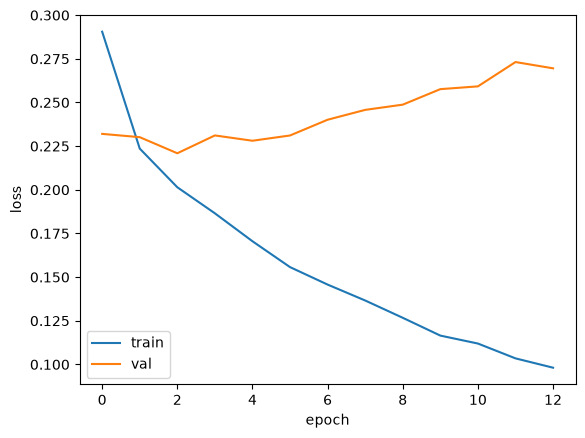

In [12]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

In [13]:
model.evaluate(test_scaled, test_target)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9115 - loss: 0.2461


[0.24605891108512878, 0.9114999771118164]